READ ME:

How do butterfly populations in North America change over time, and where can we expect them to be in the future? Our target feature is the average count of butterfly populations compared to survey durations. Our plot in phase 2 shows a relationship between these two properties. After completing this phase3 assignment, and further eliminating entries that complicated analysis, we ended up with a row x col shape of 6509 x 30.

Part 1: From Phase 2: 

In [1]:
import sys 
import numpy as np 
import pandas as pd
import matplotlib 
import matplotlib.pyplot as plt

ButterflyData = pd.read_csv('ButterflyDataCleaned.csv')
GTButterflyPop = pd.read_csv('GoogleTrendsButterflyPopulation.csv')

print(f"Shape of ButterflyData: {ButterflyData.shape}")
print(f"Shape of GTButterflyPop: {GTButterflyPop.shape}")
print(ButterflyData.dtypes)
print(GTButterflyPop.dtypes)

print("All imports successful.")

Shape of ButterflyData: (1319181, 5)
Shape of GTButterflyPop: (205, 2)
region                       str
Reported species name        str
count                      int64
duration                 float64
date                         str
dtype: object
Time                      str
Butterfly Population    int64
dtype: object
All imports successful.


In [2]:
#Convert date/Time in both csv files to data datatypes
ButterflyData['date'] = pd.to_datetime(ButterflyData['date'])
GTButterflyPop['Time'] = pd.to_datetime(GTButterflyPop['Time'])
print(ButterflyData.dtypes)
print(GTButterflyPop.dtypes)

region                              str
Reported species name               str
count                             int64
duration                        float64
date                     datetime64[us]
dtype: object
Time                    datetime64[us]
Butterfly Population             int64
dtype: object


In [3]:
#Rename GT Time column to date
GTButterflyPop = GTButterflyPop.rename(columns={'Time': 'date'})

#Rename Butterfly Population interest
GTButterflyPop = GTButterflyPop.rename(columns={'Butterfly Population': 'Butterfly pop. interest'})

#Merge
merged = pd.merge(
    ButterflyData, 
    GTButterflyPop, 
    on = 'date', 
    how = 'inner'
)

#Show data info
print(f"Rows in ButterflyData: {len(ButterflyData):,}")
print(f"Rows in GTButterflyPop: {len(GTButterflyPop):,}")
print(f"Rows in merged: {len(merged):,}")

#Remove duration values that make no sense
merged = merged[merged['duration'] <= 600]
merged = merged[merged['duration'] > 0]

Rows in ButterflyData: 1,319,181
Rows in GTButterflyPop: 205
Rows in merged: 36,824


In [4]:
merged.shape
merged.info()
merged.describe()

<class 'pandas.DataFrame'>
Index: 6506 entries, 0 to 24074
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   region                   6506 non-null   str           
 1   Reported species name    6506 non-null   str           
 2   count                    6506 non-null   int64         
 3   duration                 6506 non-null   float64       
 4   date                     6506 non-null   datetime64[us]
 5   Butterfly pop. interest  6506 non-null   int64         
dtypes: datetime64[us](1), float64(1), int64(2), str(2)
memory usage: 355.8 KB


,count,duration,date,Butterfly pop. interest
count,6506.000000,6506.000000,6506,6506.000000
mean,5.582539,80.015217,2014-03-09 10:22:36.778358,23.308331
min,0.000000,1.000000,2004-06-01 00:00:00,0.000000
25%,1.000000,60.000000,2010-07-01 00:00:00,0.000000
50%,2.000000,75.000000,2015-08-01 00:00:00,26.000000
75%,5.000000,99.750000,2017-10-01 00:00:00,34.000000
max,264.000000,218.000000,2020-10-01 00:00:00,75.000000
std,12.777912,31.516821,NaN,20.490561


## Phase 3

In [5]:
correlation = merged['count'].corr(merged['Butterfly pop. interest'])
print(f'Correlation between X and Y: {correlation:.4f}')

Correlation between X and Y: 0.0026


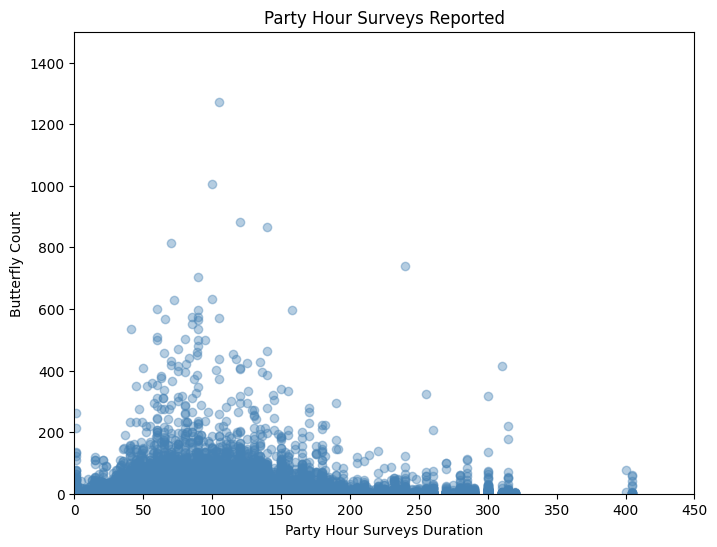

In [6]:
#EDA 5 How does surveys such as party hour correspond with the number of butterflies being reported?
import matplotlib_inline
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6))
ax.scatter(ButterflyData['duration'], ButterflyData['count'], alpha=0.4, color='steelblue')
ax.set_title('Party Hour Surveys Reported')
ax.set_xlabel('Party Hour Surveys Duration')
ax.set_ylabel('Butterfly Count')
ax.set_xlim(0, 450) #this helps set a limit for the x values so plot is not scattering in one place
ax.set_ylim(0, 1500) #this helps set a limit for the y values 
plt.show() 

I am predicting the count of butterflies using duration because my Phase 2 EDA showed a scatter plot in my EDA that represents a relationship between the surveys duration and the count of butterflies. 

Part 2: 

In [7]:
constant_prediction = merged['count'].mean()
merged['pred_constant'] = constant_prediction
merged['error'] = merged['count'] - merged['pred_constant']
merged['squared_error'] = merged['error'] ** 2

mse_constant = merged['squared_error'].mean()
rmse_constant = mse_constant **0.5 

print(f"MSE: {mse_constant}")
print(f"RMSE: {rmse_constant}")

MSE: 163.24995026936756
RMSE: 12.776930393070456


The values of the MSE are high. This is because of the butterfly count. The RMSE constant values are 12.7769 which represents the number of butterflies that are counted. These numbers are our baseline and any model we build must beat this number to be considered useful. 

Part 3A: 

In [8]:
def mse(y, yhat):
 return np.mean((y - yhat) ** 2)

def rmse(y, yhat):
 return np.sqrt(mse(y, yhat))

print(f"MSE {mse(merged['count'], merged['pred_constant'])}")
print(f"MSE {rmse(merged['count'], merged['pred_constant'])}")

MSE 163.24995026936756
MSE 12.776930393070456


The MSE is measuring the averaged squared errors. We square the errors instead of averaging them because squaring prevents postive and negative residual errors. The RMSE tells us the errors in the butterfly count from the original units. 

Part 3B: 

In [9]:
import numpy as np
import plotly.graph_objs as go
a_values = np.linspace(-50, 50, 100)
b_values = np.linspace(-1, 1, 100)
(A, B) = np.meshgrid(a_values, b_values)
MSE_grid = np.array([
 mse(merged['count'], a + b * merged['duration'])
 for a, b in zip(A.flatten(), B.flatten())
]).reshape(A.shape)


In [10]:
import matplotlib.pyplot as plt

fig = go.Figure(data = [go.Surface(z=MSE_grid, x=a_values, y=b_values)])

fig.update_layout (
    title = 'Loss',
    scene = dict(
        xaxis_title = 'A',
        yaxis_title = 'B',
        zaxis_title = 'MSE'
    )
)
fig.show()

The x axis represents the intercept value of A. The y axis represents the intercept value of B. The z axis represents the MSE which shows the error in the model. The minimum is at the MSE lowest value. It is where the optimal slope and interceptions are. It gives a best fit for predicting the butterfly count from the survey duration. If we used a different loss function, the surface would have a different shape. It would have been less smooth and the optimization would be harder. 

Part 4A: 

In [11]:
def standard_units(x):
 return (x - np.mean(x)) / np.std(x)

def correlation(x, y):
 return np.mean(standard_units(x) * standard_units(y))

def slope(x, y):
 return correlation(x, y) * np.std(y) / np.std(x)

def intercept(x, y):
 return np.mean(y) - slope(x, y) * np.mean(x)

merged_model = merged[['duration', 'count']]

x = merged_model['duration']
y = merged_model['count']

slopeA = slope(x, y)
interceptB = intercept(x, y)

print(f'Slope: {slopeA}')
print(f'Intercept: {interceptB}')

Slope: 0.025515097239611432
Intercept: 3.5409431592530467


predicted [count] = [0.025515097239611432] + [3.5409431592530467] * [duraton]

The number we got for the intercept represents when the survey duration is at zero minutes. When observing the data, the survey duration is increasing every minute and the  butterfly count is decreasing. 

Part 4B: 

In [12]:
from sklearn.linear_model import LinearRegression
merged_model = merged[['count', 'duration']].dropna()

model = LinearRegression()
model.fit(merged_model[['duration']], merged_model['count'])
print(model.intercept_)
print(model.coef_)

3.5409431592530396
[0.0255151]


The sklearn slope matches the manual slope and intercept. The slopes have given us a 0.0255151 and an intercept of 3.5409431592530396

Part 4C: 

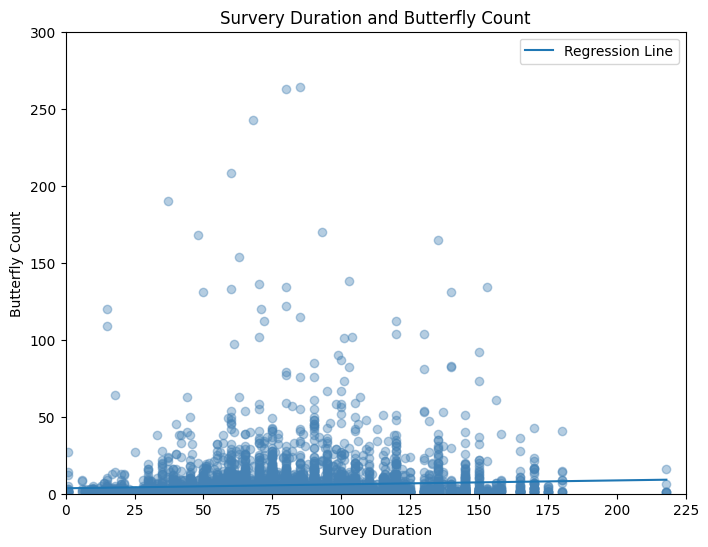

In [13]:
import matplotlib.pyplot as plt
import matplotlib_inline
import numpy as np

fig , ax  = plt.subplots(figsize = (8,6))

ax.scatter(merged_model['duration'], merged_model['count'], alpha = 0.4, color='steelblue')
x_line = np.linspace(merged_model['duration'].min(), merged_model['duration'].max())
y_line = interceptB + slopeA * x_line
ax.plot(x_line, y_line, label='Regression Line')
ax.set_title('Survery Duration and Butterfly Count')
ax.set_xlabel('Survey Duration')
ax.set_ylabel('Butterfly Count')
ax.set_xlim(0, 225)
ax.set_ylim(0, 300)
ax.legend()
plt.show()

In the scatter plot, the intercept line is shown in a straight line at the bottom. The data is more clustered around in the bottom and around the middle. The model is underpredicting the butterfly counts. The regions are also wrong especially for the survey durations that are longer. Also, the butterfly count is higher when the survey is longer. This means that the regression line is not capturing all of the trends and missing the higher butterfly count observations. 

Part 5:

In [14]:
#Part 5A:

#Linear regression predictions
merged_model['pred_linear'] = model.predict(merged_model[['duration']])

#Errors
merged_model['error_linear'] = merged_model['count'] - merged_model['pred_linear']
merged_model['squared_error_linear'] = merged_model['error_linear'] ** 2

#MSE & RMSE
mse_linear = merged_model['squared_error_linear'].mean()
rmse_linear = np.sqrt(mse_linear)

#Constant Model
constant_prediction = merged_model['count'].mean()
mse_constant = np.mean((merged_model['count'] - constant_prediction) ** 2)
rmse_constant = np.sqrt(mse_constant)

#Formula given by our instructions
percent_improvement = ((mse_constant - mse_linear) / mse_constant) * 100

#Table
comparison = pd.DataFrame({
    'Model': ['Constant Model', 'Simple Linear Regression'],
    'MSE': [mse_constant, mse_linear],
    'RMSE': [rmse_constant, rmse_linear],
    'Improvement over Baseline (%)': ['N/A', f'{percent_improvement:.2f}%']
})

print(comparison)

                      Model         MSE       RMSE  \
0            Constant Model  163.249950  12.776930   
1  Simple Linear Regression  162.603385  12.751603   

  Improvement over Baseline (%)  
0                           N/A  
1                         0.40%  


Our feature did not provide useful predictive information; our correlation is weak, and our baseline hardly shifted at all. That is not to say that it was completely useless, though, since this weak slope is expected due to our right-skewed data. We also aren't taking into consideration how other factors like regions play a huge impact on butterfly populations.

In [15]:
#Part 5B

#correlation for the region and the month
merged['butterfly_region'] = merged['region'].astype('category').cat.codes 
merged['month'] = pd.to_datetime(merged['date']).dt.month

correlation_table = merged[['count', 'duration', 'Butterfly pop. interest', 'butterfly_region', 'month']].corr()['count']

print(correlation_table)

count                      1.000000
duration                   0.062933
Butterfly pop. interest    0.002559
butterfly_region           0.043763
month                      0.099006
Name: count, dtype: float64


Caleb suggested to include the region feature, Zalma found the coefficient for it.
Zalma suggested to include the month feature, Caleb found the coefficient for it.

All of these features have a weak correlation, but the strongest of them is the month the survey took place. Google trends have no correlation since that revolves entirely around publicity of the butterfly population issue. I was surprised by how region was the weakest correlating feature out of the bunch. So, going forward, we will include the duration of the survey and month of the survey since they are our two strongest features.

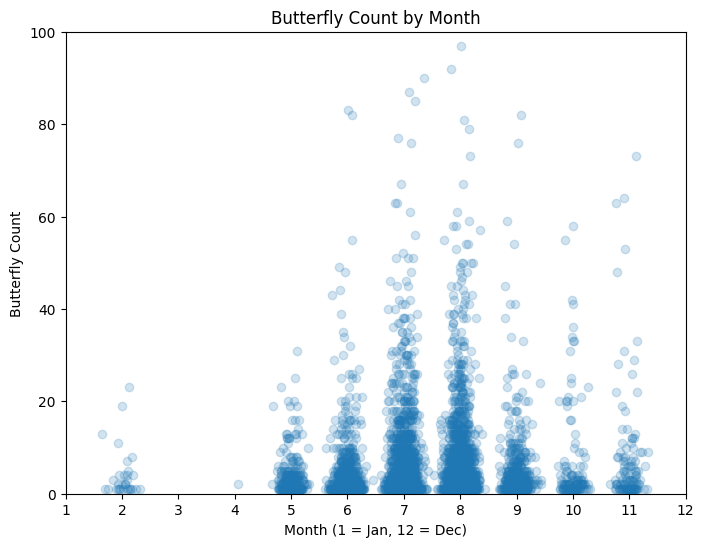

In [16]:
#Part 5C

#Butterfly Pop. vs Month is plotted below:
fig, ax = plt.subplots(figsize=(8,6))

#Jittering added for vibility, since a scatter plot was explicitly requested
month_jitter = merged['month'] + np.random.normal(0, 0.125, len(merged))
ax.scatter(month_jitter, merged['count'], alpha=0.2)

ax.set_title('Butterfly Count by Month')
ax.set_xlabel('Month (1 = Jan, 12 = Dec)')
ax.set_ylabel('Butterfly Count')

ax.set_ylim(0, 100) #Cut off at 100 to cut off outliers and better see the squished groups we'd see otherwise
plt.xticks(range(1,13))
plt.show()

Butterfly Pop. vs Survey Duration was already plotted, so it was skipped being plotted above. However, there is a clear correlation with the time of year having an impact on butterfly populations. July and August have what appear to have the higher average butterfly counts. I could be mistaken due to the volume of data we have clouding the density, but I would expect the correlation coefficient to be higher than the tiny number we got. Also, our relationship is not linear, it seems more like a wave.

Part 6:

In [17]:
#Part 6A

#Constant Model
constant_prediction = merged['count'].mean()
mse_constant = np.mean((merged['count'] - constant_prediction) ** 2)
rmse_constant = np.sqrt(mse_constant)

#Model 1
merged['pred_linear'] = model.predict(merged[['duration']])
merged['error_linear'] = merged['count'] - merged['pred_linear']
merged['squared_error_linear'] = merged['error_linear'] ** 2

mse_linear = merged_model['squared_error_linear'].mean()
rmse_linear = np.sqrt(mse_linear)
mse_1 = mse_linear
rmse_1 = rmse_linear
improve_1 = (mse_constant - mse_1) / mse_constant * 100

#Model 2
model_2 = LinearRegression()

X_2 = merged[['duration', 'month']]
y = merged['count']
model_2.fit(X_2, y)

merged['pred_2'] = model_2.predict(X_2)
merged['error_2'] = merged['count'] - merged['pred_2']
merged['squared_error_2'] = merged['error_2'] ** 2

mse_2 = merged['squared_error_2'].mean()
rmse_2 = np.sqrt(mse_2)
improve_2 = (mse_constant - mse_2) / mse_constant * 100

#Model 3
model_3 = LinearRegression()

X_3 = merged[['duration', 'month', 'butterfly_region']]
y = merged['count']
model_3.fit(X_3, y)

merged['pred_3'] = model_3.predict(X_3)
merged['error_3'] = merged['count'] - merged['pred_3']
merged['squared_error_3'] = merged['error_3'] ** 2

mse_3 = merged['squared_error_3'].mean()
rmse_3 = np.sqrt(mse_3)

improve_3 = (mse_constant - mse_3) / mse_constant * 100

#Table
comparison = pd.DataFrame({
    'Model': [
        'Constant Model',
        'Model 1 (Duration)',
        'Model 2 (Duration + Month)',
        'Model 3 (Duration + Month + Region)'
    ],
    'Features Used': [
        'none',
        'duration',
        'duration, month',
        'duration, month, region'
    ],
    'MSE': [
        mse_constant,
        mse_1,
        mse_2,
        mse_3
    ],
    'RMSE': [
        rmse_constant,
        rmse_1,
        rmse_2,
        rmse_3
    ],
    'Improvement (%)': [
        'N/A',
        f'{improve_1:.2f}%',
        f'{improve_2:.2f}%',
        f'{improve_3:.2f}%'
    ]
})

print(comparison)

                                 Model            Features Used         MSE  \
0                       Constant Model                     none  163.249950   
1                   Model 1 (Duration)                 duration  162.603385   
2           Model 2 (Duration + Month)          duration, month  160.926878   
3  Model 3 (Duration + Month + Region)  duration, month, region  160.632702   

        RMSE Improvement (%)  
0  12.776930             N/A  
1  12.751603           0.40%  
2  12.685696           1.42%  
3  12.674096           1.60%  


In [18]:
#Part 6B

#Model 1
print("Model 1 (Duration)")
print("Intercept:", model.intercept_)
print("Slope:", model.coef_)

#Model 2
print("Model 2 (Duration + Month)")
print("Intercept:", model_2.intercept_)
print("Coefficients:", model_2.coef_)
print("Features: duration, month")

#Model 3
print("Model 3 (Duration + Month + Region)")
print("Intercept:", model_3.intercept_)
print("Coefficients:", model_3.coef_)
print("Features: duration, month, butterfly_region")

Model 1 (Duration)
Intercept: 3.5409431592530396
Slope: [0.0255151]
Model 2 (Duration + Month)
Intercept: -4.680472606109917
Coefficients: [0.02699636 1.08985581]
Features: duration, month
Model 3 (Duration + Month + Region)
Intercept: -4.901178104463836
Coefficients: [0.02675262 1.08788933 0.55153665]
Features: duration, month, butterfly_region


Adding the month feature provided a somewhat noticeable improvement on our baseline improvements. Region also improved from the baseline, but by a much less significant measure. Both duration and month had their coefficients remain stable even when additional features were included. As previously established, region is the weakest of the features when compared to butterfly counts.

Part 7

MSE: 160.92687776450924
RMSE: 12.685695793471844


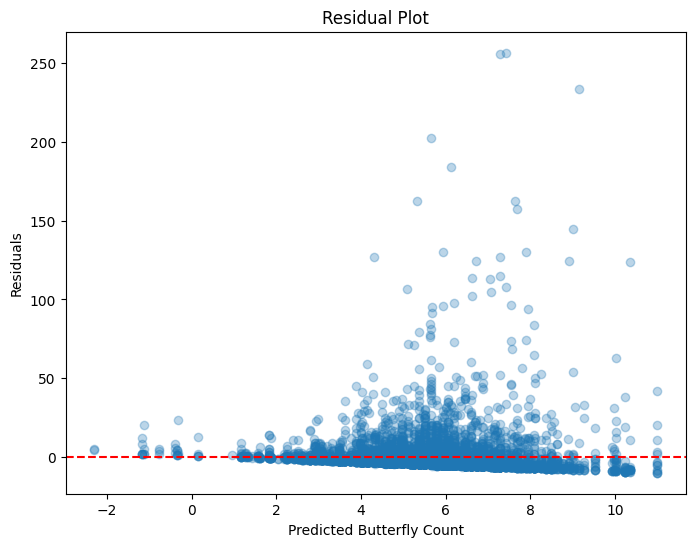

In [19]:
#Residuals for Model 2 (disregarding region's addition to model 3)
merged['pred_final'] = model_2.predict(merged[['duration', 'month']])
merged['residuals'] = merged['count'] - merged['pred_final']

merged['squared_residuals'] = merged['residuals'] ** 2
mse_final = merged['squared_residuals'].mean()
rmse_final = np.sqrt(mse_final)
print("MSE:", mse_final)
print("RMSE:", rmse_final)

plt.figure(figsize=(8,6))
plt.scatter(merged['pred_final'], merged['residuals'], alpha=0.3)
plt.axhline(0, color='red', linestyle='--')

plt.title('Residual Plot')
plt.xlabel('Predicted Butterfly Count')
plt.ylabel('Residuals')

plt.show()

With this model, we are asking if the multiple regression model can capture the relationship between butterfly count and the two features month and survey duration. Most of the residuals seem to stay relatively close to zero, but fans out a bit as butterfly counts increase, and perhaps there is a slight curve towards the middle of the x-axis. The noise further out into the higher counts suggest our model struggles with higher counts. But, I believe that a majority of our counts can be predicted, and that the outliers in our residual plot are a small fraction of the true scale of our data. I am still more confident in model 2 than the others due to the higher increase in baseline improvement compared to other models.

Part 8

P1:

The most surprising comparison between phase 2 and phase 3 of this project has been how regions are not nearly as important as other factors when it comes to predicting the butterfly count. Counts in the Canadian East stand out as having much higher averages than the rest of North America, followed by 3 medium averaged regions, and the rest being relatively low. I would have suspected this would result in a higher correlation between region and the butterfly counts. 

Correlation between butterfly count and warmth rank: -0.0644


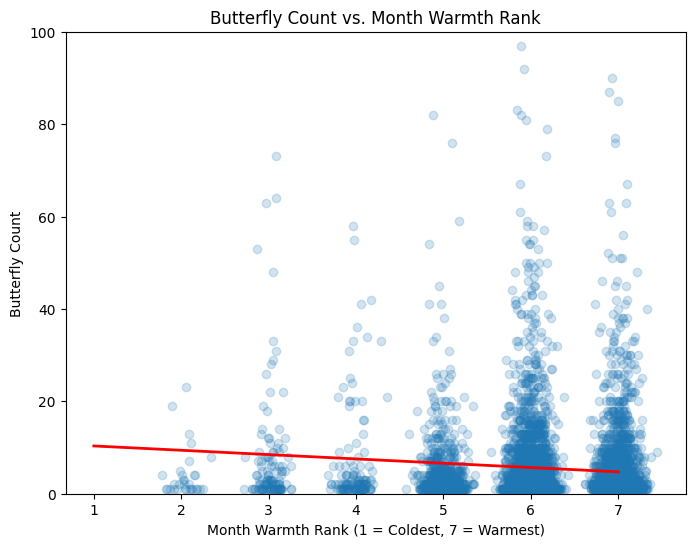

Intercept: 9.575737269433173
Coefficients: [ 0.02807651 -1.02460279]
MSE: 161.7972253623278
RMSE: 12.719953827051723
Improvement: 0.89%


In [20]:
#Feature 1, engineered by Caleb, computed by Zalma
#Feature: Sort months from coldest to hottest for NA

#Map months by warmth
warmth_map = {
    1: 1,   #January
    2: 2,   #February
    3: 3,   #March
    4: 4,   #April
    5: 5,   #May
    6: 6,   #June
    7: 7,   #July (Warmest)
    8: 6,   #August
    9: 5,   #September
    10: 4,  #October
    11: 3,  #November
    12: 2   #December
}
merged['warmth_rank'] = merged['month'].map(warmth_map)

#Correlation computation
warmth_corr = merged['warmth_rank'].corr(merged['count'])
print(f"Correlation between butterfly count and warmth rank: {warmth_corr:.4f}")

#Visualization
fig, ax = plt.subplots(figsize=(8,6))

warmth_jitter = merged['warmth_rank'] + np.random.normal(0, 0.125, len(merged))
ax.scatter(warmth_jitter, merged['count'],alpha=0.2)

#Regression line
x = np.linspace(1, 7, 100)
m, b = np.polyfit(merged['warmth_rank'], merged['count'], 1)

ax.plot(x, m*x+b, color='red', linewidth=2)

ax.set_title("Butterfly Count vs. Month Warmth Rank")
ax.set_xlabel("Month Warmth Rank (1 = Coldest, 7 = Warmest)")
ax.set_ylabel("Butterfly Count")
ax.set_ylim(0,100)

plt.show()

#Fit into model
model_warmth = LinearRegression()
X_warmth = merged[['duration', 'warmth_rank']]
model_warmth.fit(X_warmth, merged['count'])

merged['pred_warmth'] = model_warmth.predict(X_warmth)
merged['error_warmth'] = merged['count'] - merged['pred_warmth']
merged['sq_error_warmth'] = merged['error_warmth']**2

mse_warmth = merged['sq_error_warmth'].mean()
rmse_warmth = np.sqrt(mse_warmth)
improvement = (mse_constant - mse_warmth) / mse_constant * 100

print("Intercept:", model_warmth.intercept_)
print("Coefficients:", model_warmth.coef_)
print("MSE:", mse_warmth)
print("RMSE:", rmse_warmth)
print(f"Improvement: {improvement:.2f}%")

Correlation between butterfly count and log(duration): 0.0567


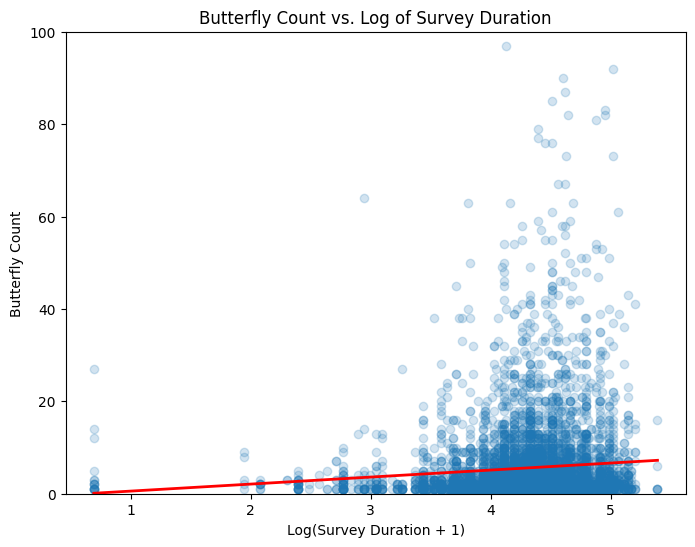

Intercept: -9.290953137639296
Coefficients: [1.58896648 1.08082675]
MSE: 161.07485239272418
RMSE: 12.691526795178119
Improvement: 1.33%


In [21]:
#Feature 2, engineered by Zalma, computed by Caleb
#Feature: Log of Survey Duration

#Create log_duration
merged['log_duration'] = np.log1p(merged['duration'])

#Calculate Correlation
log_corr = merged['log_duration'].corr(merged['count'])
print(f"Correlation between butterfly count and log(duration): {log_corr:.4f}")

#Visualization
fig, ax = plt.subplots(figsize=(8,6))

ax.scatter(merged['log_duration'],merged['count'],alpha=0.2,)

m, b = np.polyfit(merged['log_duration'], merged['count'], 1)
x = np.linspace(merged['log_duration'].min(),merged['log_duration'].max(),100)
ax.plot(x, m*x+b, color='red', linewidth=2)

ax.set_title("Butterfly Count vs. Log of Survey Duration")
ax.set_xlabel("Log(Survey Duration + 1)")
ax.set_ylabel("Butterfly Count")
ax.set_ylim(0,100)

plt.show()

#Fit into model
model_log = LinearRegression()
X_log = merged[['log_duration', 'month']]
model_log.fit(X_log, merged['count'])

merged['pred_log'] = model_log.predict(X_log)
merged['error_log'] = merged['count'] - merged['pred_log']
merged['sq_error_log'] = merged['error_log']**2

mse_log = merged['sq_error_log'].mean()
rmse_log = np.sqrt(mse_log)
improvement = (mse_constant - mse_log) / mse_constant * 100

print("Intercept:", model_log.intercept_)
print("Coefficients:", model_log.coef_)
print("MSE:", mse_log)
print("RMSE:", rmse_log)
print(f"Improvement: {improvement:.2f}%")

P2:

The first feature came with a very surprising result of a negative slope. Through previous plots we were under the impression that hotter months resulted in more butterfly counts during surveys, but this doesn't seem to be the case and may just be a result of how crowded all the data is. Perhaps warmer months lead to a wider variety of butterfly counts but on average don't change them as much, and these higher varieties could be a result of migrations such as how the Monarchs do in Autumn. The butterfly count vs log of survey duration gave us the strongest slope that we have seen in any of our visualizations thus far. It also gave us a relatively significant improve percentage from our constant model. Next time, we may be more careful about how broad our questions are. Data on butterfly populations seem to be far more complicated than previously expected, and rely on many variables. Collaborative feature engineering allows for a wider variety of ideas, variable combinations, and ways to transform data that can reveal important patterns.

In [22]:
print(merged.shape)

(6506, 31)


## Phase 4

Part 1

The set up for phase 3 was to clean the data and then have our model based on all the data that we had. This works fine in hindsight, but does not mean it will work as a true model that can predict outcomes. The train/test split will allow us to train our model on portions of data, and test to see how it compares to other portions of the data. Since our previous models had a significant error with few improvements from the constant model, I am not expecting dramatic changes, but ultimately I do believe improvements will drop slightly from what we had optimistically estimated before.

In [23]:
from sklearn.model_selection import train_test_split

#Phase 3 Part 6B Features
X = merged[['duration', 'month']]
y = merged['count']

#Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)

#Verifying Expected Shapes
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training shape:", y_train.shape)
print("Testing shape:", y_test.shape)

#Linear Regression
model_slr = LinearRegression()
model_slr.fit(X_train[['duration']], y_train)
y_pred_slr = model_slr.predict(X_test[['duration']])

mse_slr_test = np.mean((y_test - y_pred_slr) ** 2)
rmse_slr_test = np.sqrt(mse_slr_test)

#Multi Linear Regression
model_multi = LinearRegression()
model_multi.fit(X_train, y_train)
y_pred_multi = model_multi.predict(X_test)

mse_multi_test = np.mean((y_test - y_pred_multi) ** 2)
rmse_multi_test = np.sqrt(mse_multi_test)

#Results
print("SLR")
print("Test MSE:", mse_slr_test)
print("Test RMSE:", rmse_slr_test)

print("MLR")
print("Test MSE:", mse_multi_test)
print("Test RMSE:", rmse_multi_test)

Training shape: (5204, 2)
Testing shape: (1302, 2)
Training shape: (5204,)
Testing shape: (1302,)
SLR
Test MSE: 165.19115382673942
Test RMSE: 12.85267107751301
MLR
Test MSE: 162.68383850500913
Test RMSE: 12.754757485150751


In phase 3, we had RMSE values of 12.751603 and 12.685696 for the SLR and MLR. During this train/test split, though, those values are slightly higher at 12.852671 and 12.754757. The gap between the two remained relatively small, although slightly grew between the train/test splits. This suggests that the MLR model preforms better on unseen data than the SLR model.

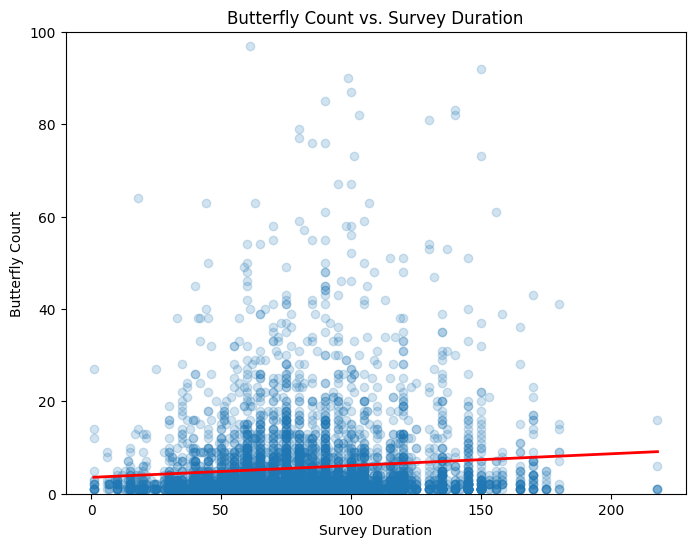

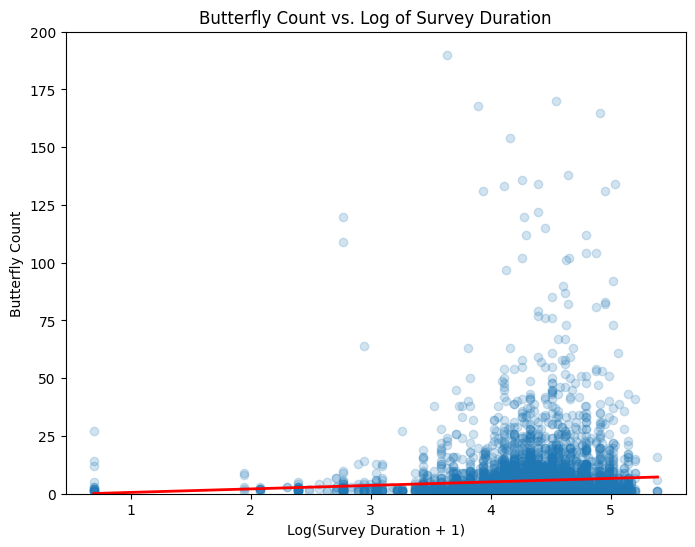

In [24]:
#3A

#Count vs Survey Duration
fig, ax = plt.subplots(figsize=(8,6))

ax.scatter(merged['duration'],merged['count'],alpha=0.2,)

m, b = np.polyfit(merged['duration'], merged['count'], 1)
x = np.linspace(merged['duration'].min(),merged['duration'].max(),100)
ax.plot(x, m*x+b, color='red', linewidth=2)

ax.set_title("Butterfly Count vs. Survey Duration")
ax.set_xlabel("Survey Duration")
ax.set_ylabel("Butterfly Count")
ax.set_ylim(0,100)

plt.show()

#Count vs log(Survey Duration)
fig, ax = plt.subplots(figsize=(8,6))

ax.scatter(merged['log_duration'],merged['count'],alpha=0.2,)

m, b = np.polyfit(merged['log_duration'], merged['count'], 1)
x = np.linspace(merged['log_duration'].min(),merged['log_duration'].max(),100)
ax.plot(x, m*x+b, color='red', linewidth=2)

ax.set_title("Butterfly Count vs. Log of Survey Duration")
ax.set_xlabel("Log(Survey Duration + 1)")
ax.set_ylabel("Butterfly Count")
ax.set_ylim(0,200)

plt.show()

The comparison between the two graphs shows less noise on the Butterfly Count vs. Log of Survey Duration scatterplot. I don't think I would call this relationship linear since I believe the variety in longer durations fans out rather than consistently being higher. However, the trend is more apparent when butterfly count is compared to the log of survey duration than just the regular survey duration feature.

In [25]:
#3B

#Interaction term
merged['duration_month_interaction'] = merged['duration'] * merged['month']

#Train model with interaction term
model_interaction = LinearRegression()
X_interaction = merged[['duration', 'month', 'duration_month_interaction']]
y = merged['count']
model_interaction.fit(X_interaction, y)

#Predictions
merged['pred_interaction'] = model_interaction.predict(X_interaction)

#Error
merged['error_interaction'] = merged['count'] - merged['pred_interaction']
merged['sq_error_interaction'] = merged['error_interaction'] ** 2

mse_interaction = merged['sq_error_interaction'].mean()
rmse_interaction = np.sqrt(mse_interaction)

print("Intercept:", model_interaction.intercept_)
print("Coefficients:", model_interaction.coef_)
print("MSE:", mse_interaction)
print("RMSE:", rmse_interaction)

Intercept: -5.171223876758369
Coefficients: [ 3.34440883e-02  1.15597741e+00 -8.70639476e-04]
MSE: 160.92562361557071
RMSE: 12.685646361757478


It makes sense to have these two variables interact since surveying for longer periods of time during different times of year may result in a higher butterfly count. Surveying in the dead of winter will have a lower rate of butterflies per hour, whereas in less harsh times of the year there may be a much higher rate.

Engineered Model Test MSE: 162.6919780639874
Engineered Model Test RMSE: 12.755076560491018


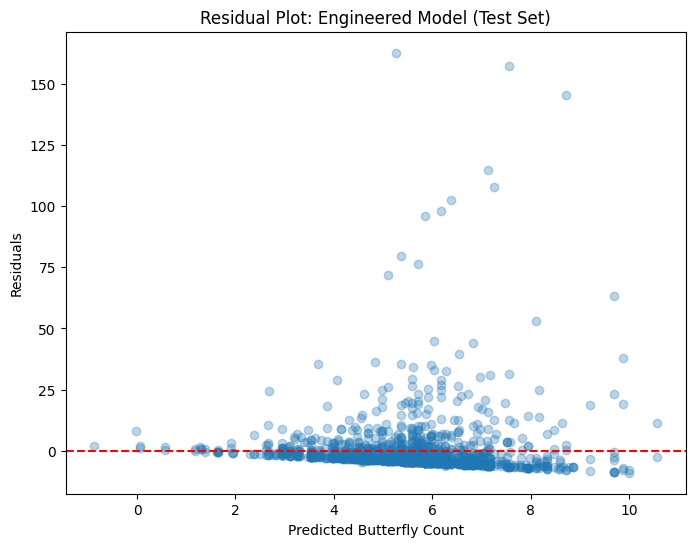

In [26]:
#Part 4
X_engineered = merged[
    ['duration',
     'month',
     'log_duration',
     'duration_month_interaction']
]

#Train/Test from Part 2
X_train_eng = X_engineered.loc[X_train.index]
X_test_eng = X_engineered.loc[X_test.index]

#Train
model_eng = LinearRegression()
model_eng.fit(X_train_eng, y_train)

#Predictions
y_pred_eng = model_eng.predict(X_test_eng)

#Errors
mse_eng = np.mean((y_test - y_pred_eng) ** 2)
rmse_eng = np.sqrt(mse_eng)
print("Engineered Model Test MSE:", mse_eng)
print("Engineered Model Test RMSE:", rmse_eng)

#Residual plot
residuals_eng = y_test - y_pred_eng

plt.figure(figsize=(8,6))
plt.scatter(y_pred_eng, residuals_eng, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')

plt.title("Residual Plot: Engineered Model (Test Set)")
plt.xlabel("Predicted Butterfly Count")
plt.ylabel("Residuals")

plt.show()

Our Phase 3 residual plot had a MSE and RMSE of 160.926877 and 12.685695, whereas our new residual plot actually has slightly worse values at 162.691978 and 12.755076. Both residual plots keep that similar pattern where they fan out and residuals increase as butterfly counts grow. Visually, though, it does appear like the newer residual plot has less of a noisy cloud above it compared to our previous residual plot. Our model is likely missing many important variables, which is not surprising given how complicated ecosystems can be, especially during times of significant human interference.

In [37]:
#part 5 Ridge and Lasso
from sklearn.linear_model import LinearRegression, Ridge, Lasso

#ridge
ridge1 = Ridge(alpha = 1.0)
ridge1.fit(X_train_eng, y_train)
rmse_ridge1 = np.sqrt(np.mean((y_test - ridge1.predict(X_test_eng))**2))

ridge2 = Ridge(alpha = 5.0)
ridge2.fit(X_train_eng, y_train)
rmse_ridge2 = np.sqrt(np.mean((y_test - ridge2.predict(X_test_eng))**2))

print(f"Ridge RMSE Test (Alpha 1.0): {rmse_ridge1}")
print(f"Ridge RMSE Test (Alpha 5.0): {rmse_ridge2}")
print("--")
print("Ridge Coeff (Alpha 1.0): ",ridge1.coef_)
print("Ridge Coeff (Alpha 5.0): ",ridge2.coef_)

#lasso
lasso1 = Lasso(alpha = 1.0)
lasso1.fit(X_train_eng, y_train)
rmse_lasso1 = np.sqrt(np.mean((y_test - lasso1.predict(X_test_eng))**2))

lasso2 = Lasso(alpha = 5.0)
lasso2.fit(X_train_eng, y_train)
rmse_lasso2 = np.sqrt(np.mean((y_test - lasso2.predict(X_test_eng))**2))

print(f"Lasso RMSE Test (Alpha 1.0): {rmse_lasso1}")
print(f"Lasso RMSE Test (Alpha 5.0): {rmse_lasso2}")
print("--")
print("Lasso Coeff (Alpha 1.0): ", lasso1.coef_)
print("Lasso Coeff (Alpha 5.0): ", lasso2.coef_)



Ridge RMSE Test (Alpha 1.0): 12.75508245954013
Ridge RMSE Test (Alpha 5.0): 12.75510628599772
--
Ridge Coeff (Alpha 1.0):  [ 2.86170405e-02  1.04720506e+00  1.08114299e-01 -4.26472841e-04]
Ridge Coeff (Alpha 5.0):  [ 2.83763431e-02  1.04389334e+00  1.05969293e-01 -3.90097488e-04]
Lasso RMSE Test (Alpha 1.0): 12.777250585714775
Lasso RMSE Test (Alpha 5.0): 12.794444332738445
--
Lasso Coeff (Alpha 1.0):  [-0.04797174  0.         -0.          0.01020142]
Lasso Coeff (Alpha 5.0):  [-0.01902832  0.         -0.          0.00679982]


The Ridge gave a RMSE test of 12.755 for alpha 1.0 and a 12.755 for alpha 5.0. The Lasso gave a RMSE test of 12.777 for alpha 1.0 and 12.794 for alpha 5.0. In comparison to the engineered OLS model with a RMSE test of 12.755, the Ridge regression performed the same number in both of its alpha bounds. The Lasso regression performed slightly worse in both of its alpha bounds. However, the Lasso did eliminate features entirely by driving their coefficients to zero. The alpha bounds 1.0 and 5.0 both zeroed out their coefficients especially zeroing out the log_duration and the month. 

In [ ]:
#part 6 comparison table
from sklearn.linear_model import LinearRegression

#constant model
constant_pred = y_train.mean()

mse_train_constant = np.mean((y_train - constant_pred)**2)
rmse_train_constant = np.sqrt(mse_train_constant)
rmse_test_constant = np.sqrt(np.mean((y_test - constant_pred) ** 2))

print(f"Constant Train MSE: {mse_train_constant}")
print(f"Constant Train RMSE: {rmse_train_constant}")
print(f"Constant Test RMSE: {rmse_test_constant}")

#simple linear model
X_train_simple_linear = X_train[['duration']]
X_test_simple_linear = X_test[['duration']]

model_simple_linear = LinearRegression()
model_simple_linear.fit(X_train_simple_linear, y_train)

pred_train_simple_linear =  model_simple_linear.predict(X_train_simple_linear)
pred_test_simple_linear = model_simple_linear.predict(X_test_simple_linear)

mse_train_simple_linear = np.mean((y_train - pred_train_simple_linear)**2)
rmse_train_simple_linear = np.sqrt(mse_train_simple_linear)
rmse_test_simple_linear = np.sqrt(np.mean((y_test - pred_test_simple_linear) ** 2))
print("--")
print(f"Simple Linear Regression MSE Train: {mse_train_simple_linear}")
print(f"Simple Linear Regression RMSE Train: {rmse_train_simple_linear}")
print(f"Simple Linear Regression RMSE Test: {rmse_test_simple_linear}")

#multi-linear model
X_train_multi_model = X_train[['duration', 'month']]
X_test_multi_model = X_test[['duration', 'month']]

model_multi = LinearRegression()
model_multi.fit(X_train_multi_model, y_train)

pred_train_multi = model_multi.predict(X_train_multi_model)
pred_test_multi = model_multi.predict(X_test_multi_model)

mse_train_multi = np.mean((y_train - pred_train_multi)**2)
rmse_train_multi = np.sqrt(mse_train_multi)
rmse_test_multi = np.sqrt(np.mean((y_test - pred_test_multi) ** 2))
print("--")
print(f"Multi-Feature Model MSE Train: {mse_train_multi}")
print(f"Multi-Feature Model RMSE Train: {rmse_train_multi}")
print(f"Multi-Feature Model RMSE Test: {rmse_test_multi}")

#engineered model
model_eng = LinearRegression()
model_eng.fit(X_train_eng, y_train)

pred_train_eng = model_eng.predict(X_train_eng)
mse_train_eng = np.mean((y_train - pred_train_eng)**2)
rmse_train_eng = np.sqrt(mse_train_eng)
rmse_test_eng = np.sqrt(np.mean((y_test - model_eng.predict(X_test_eng)) ** 2))
print("--")
print(f"Engineered Model MSE Train: {mse_train_eng}")
print(f"Engineered Model RMSE Train: {rmse_train_eng}")
print(f"Engineered Model RMSE Test: {rmse_test_eng}")




Constant Train MSE: 162.58684799311828
Constant Train RMSE: 12.750954787509768
Constant Test RMSE: 12.88074255049171
--
Simple Linear Regression MSE Train: 161.9585474887629
Simple Linear Regression RMSE Train: 12.726293548742419
Simple Linear Regression RMSE Test: 12.85267107751301
--
Multi-Feature Model MSE Train: 160.4999951089311
Multi-Feature Model RMSE Train: 12.668859266284834
Multi-Feature Model RMSE Test: 12.754757485150751
--
Engineered Model MSE Train: 160.49922693960093
Engineered Model RMSE Train: 12.66882894902291
Engineered Model RMSE Test: 12.755076560491018



From the comparison table, the multi-feature model performed the best on the test set. This is because it consisted of the lowest RMSE test 12.75 which is close to the number on our engineered model RMSE test. Feature engineering did not provide much of a meaningful improvement over the Phase 3 multi-feature-model. Adding the durations of the month and the log_duration did not make a difference between the MSE trains because they both printed a result of 160.49. The gap between the train RMSE and the test RMSE is consistent across the models. This indictates that the models are not overfitting but rather underfitting. This is because the models do not have a strong linear relation between the features we added such as the log_duration and the duration month to the relationship of the butterfly counts. 

#part 7a: Zalma 

The question I am trying to answer is how does the count of butterfly towards the butterfly population vary from surveys such as the Party Hour Survey. The data I used to answer this question came from an article titled "figshare" who provided a raw butterfly observation dataset with a Google Trends dataset. These datasets represent butterfly monitoring throughout the U.S. The target variable that I created is called 'count' which kept in track of the number of butterflies that are being reported through surveys. This target variable is worth prediciting because it is one of the main targets used to track the number of butterfly populations across the region.

#part 7b: Zalma

The most important pattern that I found in the Phase 2 EDA was how surveys such as party hour corresponds with the number of butterfly counts being reported. I noticed in the scatter plot of the EDA 5 that the number of butterflies that are being reported are low. The counts are staying low especially when the duration of the survey is under 60 minutes. High butterfly counts such as 800 or even 600 rarely pop up in the scatter plot because the surveys no matter how long they are, are still reporting a low count of butterflies. This EDA shaped features such as the correlation table. By creating a correlation table for the region in Part 5B, it showed that the butterfly region had a weak relation with the butterfly count. This shaped my choice of adding additional features like 'duration' to help future engineered models to show a stronger relationship of butterfly counts. It also shaped my choice of feature in Phase 3 Part 1 because I used the feature 'duration' to show the relationship it has with the butterfly counts.

#part 7c: Zalma

In the Phase 3 Simple Linear Regression Model, it predicted an intercept of 3.5409 and a slope of 0.0255. This gave a model equation of  0.0255 + 3.5409  * duration. From the comparison table in Part 6, the simple linear regression model tested an RMSE of 12.85 and the constant model had an RMSE test of 12.88. You can see that the simple linear regression model performed slightly better than the constant model. The model has evolved from a single feature 'duration' in Phase 3 by adding onto the 'month' feature in the Part 6B multi-feature selection to the Phase 4 engineered model. This is because in the engineered model, I created a 'log_duration' feature that reshaped the survey duration using log. It is used to see if the non-linear relationship has more of a stronger relationship with the butterfly count. The feature engineering that I tried in Phase 3 did not help because when looking at the comparison table, you can see that the engineered model predicted a MSE train of 160.4992 and the Multi-Feature Model predicted a MSE Train of 160.4992. The added complexity did not improve the performance of the  models. My best model was the Multi-Feature Model compared to the constant model because it gave a RMSE test of 12.75 and the constant model gave a RMSE test of 12.88. This means that the Multi-Feature Model is closer to the true count of the butterflies than the constant model. 

#part 7d: Zalma

My residual plot from Part 4 shows a scatter plot that represents the residuals predicting higher counts for butterflies. It starts to fan out with points hitting up to 150. This means that the model is underpredicting the butterfly counts especially on surveys that have a high count of butterflies. This pattern tells me that the model is missing factors that could explain why it is causing the residual to fan out and predict unlikely high butterfly counts. These high counts can be where features such as the duration, month, or even region show a weak correlation with the butterfly count. 

#part 7e: Zalma

One additional feature I would add is a weather feature. This is because butterfly counts can vary depending on the weather conditions on the days the surveys are being reported. A modeling technique I would use beyond simple linear regression would be a non-linear model such as a decision tree which can help better capture the complex relationships in our features. In part 5, the Ridge and the Lasso showed that the model did not fully improve the performance because both the Ridge and the engineered OLS model have a RMSE test of 12.7555. Using a decision tree could help capture the complex relationships especially in the residual scatter plot, which fans out and shows underpredicted high butterfly counts. 

# Part 7: Caleb

7a:

Originally, I wanted to ask how butterfly populations have been changing over the past few years, but it occurred to be that a solid relationship between butterfly counts and surveys details such as their duration would have to be discovered first. I cannot make meaningful claims on butterfly population trends without understanding the parallels between those counts and other features that were given to us in a database used for the article "Rapid Butterfly Declines Across The United States During the 21st Century". This is an important feature to predict so that we may monitor the trends in populations and biodiversity.

7b:

In Phase 2 we found that some regions have far higher average butterfly counts than others, and that survey has a subtle but positive relationship with the number of butterflies counted during a survey. We used this for phase 3 since it seemed the be the most obvious relationship out of anything our EDA equations revealed to us. It was chosen over region since region is categorical. Phase 3 part 5B revealed that months was the next most important feature to include due to its higher correlation than other features.

7c:

In phase 3, our linear regression model had an equation of 0.025515x + 3.540943, which gave us a 0.40% improvement based on the constant model. The improvement may be tiny, but the slope is so small that it is nearly flat, so that small improvement is expected. The model evolved as we attempted to add other features that weren't just survey duration, such as the time of year and region. Both of these features helped, but the month of the year saw a much higher improvement from the baseline than region. Our month feature increased our improvement by 1.02% on top of the linear regression model, while adding the month feature increased our improvement by only 0.18%. We stuck with the 2nd model that compared butterfly count vs survey duration and month of the year to get a total improvement of 1.42%.

7d:

The model struggled greatly with predicting higher butterfly counts, and it creates a fanning out pattern. This is due to longer survey durations resulting in a larger variety of butterfly counts. I cannot say confidently what I believe to be the missing feature that could be causing this fanning out pattern, all I can say is that there is a lack of a certain variable being controlled for more fair comparisons.

7e:

This database has been having butterfly counts added to it for a long time, across many volunteers, organizations, and regions. There are undoubtedly many features that could be added to our model, but one I think that should be included next is a category that is used to compare methods used by different surveyors. Different volunteers have different systems, and many of them couldn't even agree on how to format their data, suggesting a high level of independence during these surveys and a lack of strict structure. Our model did not perform well, and perhaps is a result of how complicated of a number this is to predict mixed with how broad of a net our model is casting.